<IPython.core.display.Javascript object>


0: 480x640 1 person, 1 airplane, 1 cell phone, 405.1ms
Speed: 13.1ms preprocess, 405.1ms inference, 34.1ms postprocess per image at shape (1, 3, 480, 640)


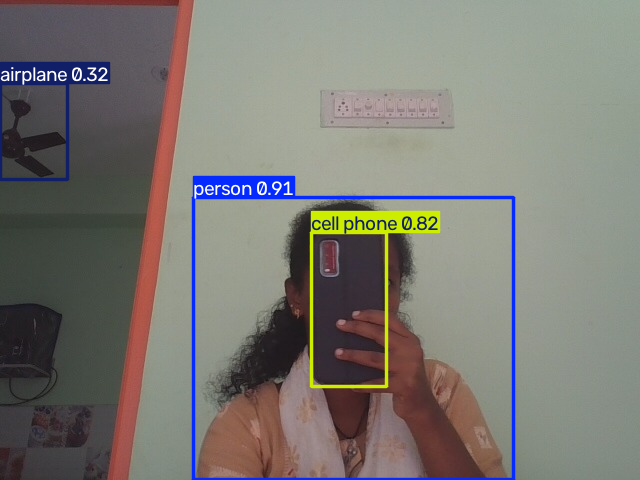

person: 91.21%
cell phone: 82.35%
airplane: 32.01%


In [3]:
# YOLO Pretrained Model - Camera Object Detection
!pip install -q ultralytics

from ultralytics import YOLO
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import numpy as np

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

# Capture image using camera
display(Javascript("""
async function captureImage() {
    const div = document.createElement('div');
    const btn = document.createElement('button');
    btn.textContent = 'Capture Image';
    div.appendChild(btn);
    const video = document.createElement('video');
    video.style.width = '400px';
    const stream = await navigator.mediaDevices.getUserMedia({video: true});
    document.body.appendChild(div);
    div.appendChild(video);
    video.srcObject = stream;
    await video.play();
    await new Promise(resolve => btn.onclick = resolve);
    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);
    stream.getTracks().forEach(track => track.stop());
    div.remove();
    return canvas.toDataURL('image/jpeg');
}
"""))

# Capture and process camera image
try:
    data = eval_js("captureImage()")
    img = cv2.imdecode(
        np.frombuffer(b64decode(data.split(',')[1]), np.uint8),
        cv2.IMREAD_COLOR
    )

    # Detect objects
    results = model.predict(img, conf=0.25)

    # Display detection output
    annotated_img = results[0].plot()
    cv2_imshow(annotated_img)

    # Print detected object names
    for box in results[0].boxes:
        name = model.names[int(box.cls[0])]
        confidence = float(box.conf[0])
        print(f"{name}: {confidence:.2%}")
except Exception as e:
    print(f"Error: {e}")
    print("Please make sure you have allowed camera permissions in your browser settings.")